In [2]:
import os
import sys
sys.path.append(os.path.abspath('C:/Users/jhous/Documents/Precise_Modules'))
from Precise import Precise
from boruta_analysis import BorutaAnalyzer
from shap_analysis import SHAPVisualizer
from reinforcement_learning import ReinforcementLearningAnalyzer
from prediction_analysis import PredictionAnalyzer
import numpy as np
import torch_directml
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

dml = torch_directml.device()
device = dml

In [13]:
df = pd.read_csv("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/GSE120575_Sade_Feldman_melanoma_single_cells_TPM_GEO.txt.gz", sep="\t",header = [0,1])
df.head()

,Unnamed: 0_level_0,A10_P3_M11,A11_P1_M11,A11_P3_M11,A11_P4_M11,A12_P3_M11,A12_P6_M11,A2_P1_M11,A2_P4_M11,A3_P1_M11,...,H12_P5_M67_L001_T_enriched,H1_P5_M67_L001_T_enriched,H2_P5_M67_L001_T_enriched,H3_P5_M67_L001_T_enriched,H4_P5_M67_L001_T_enriched,H5_P5_M67_L001_T_enriched,H6_P5_M67_L001_T_enriched,H7_P5_M67_L001_T_enriched,H8_P5_M67_L001_T_enriched,H9_P5_M67_L001_T_enriched
,Unnamed: 0_level_1,Pre_P1,Pre_P1,Pre_P1,Pre_P1,Pre_P1,Pre_P1,Pre_P1,Pre_P1,Pre_P1,...,Post_P6_T_enriched,Post_P6_T_enriched,Post_P6_T_enriched,Post_P6_T_enriched,Post_P6_T_enriched,Post_P6_T_enriched,Post_P6_T_enriched,Post_P6_T_enriched,Post_P6_T_enriched,Post_P6_T_enriched
TSPAN6,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,0.00,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,NaN
TNMD,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,0.00,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,NaN
DPM1,0.0,9.24,0.0,7.99,0.0,0.0,0.0,0.0,8.44,0.0,...,6.60,0.00,0.0,0.00,7.34,0.0,0.0,0.0,0.0,NaN
SCYL3,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,5.15,2.54,0.0,0.00,0.00,0.0,0.0,0.0,0.0,NaN
C1orf112,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,8.03,0.00,0.0,0.61,7.65,0.0,0.0,0.0,0.0,NaN


In [15]:
df_temp.shape

(16348, 35)

In [2]:
df_expr = pd.read_csv("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/GSE120575_Sade_Feldman_melanoma_single_cells_TPM_GEO.txt.gz", sep="\t", skiprows=2, header=None, index_col=0)

In [4]:
import gzip
with gzip.open("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/GSE120575_Sade_Feldman_melanoma_single_cells_TPM_GEO.txt.gz", "rt") as f:
    line1 = f.readline().strip().split("\t")
    line2 = f.readline().strip().split("\t")

In [5]:
if line1[0] in ['', '0', 'Unnamed: 0', 'Unnamed: 0_level_0']:
    line1 = line1[1:]
if line2[0] in ['', '0', 'Unnamed: 0', 'Unnamed: 0_level_1']:
    line2 = line2[1:]

In [10]:
df_expr.head()

,1,2,3,4,5,6,7,8,9,10,...,16283,16284,16285,16286,16287,16288,16289,16290,16291,16292
0,,,,,,,,,,,,,,,,,,,,,
TSPAN6,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,0.00,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,NaN
TNMD,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,0.00,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,NaN
DPM1,0.0,9.24,0.0,7.99,0.0,0.0,0.0,0.0,8.44,0.0,...,6.60,0.00,0.0,0.00,7.34,0.0,0.0,0.0,0.0,NaN
SCYL3,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,5.15,2.54,0.0,0.00,0.00,0.0,0.0,0.0,0.0,NaN
C1orf112,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,8.03,0.00,0.0,0.61,7.65,0.0,0.0,0.0,0.0,NaN


In [11]:
df_expr.index.name = None

In [12]:
df_expr.head()

,1,2,3,4,5,6,7,8,9,10,...,16283,16284,16285,16286,16287,16288,16289,16290,16291,16292
TSPAN6,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,0.00,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,NaN
TNMD,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,0.00,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,NaN
DPM1,0.0,9.24,0.0,7.99,0.0,0.0,0.0,0.0,8.44,0.0,...,6.60,0.00,0.0,0.00,7.34,0.0,0.0,0.0,0.0,NaN
SCYL3,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,5.15,2.54,0.0,0.00,0.00,0.0,0.0,0.0,0.0,NaN
C1orf112,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,...,8.03,0.00,0.0,0.61,7.65,0.0,0.0,0.0,0.0,NaN


In [13]:
num_cells_in_data = df_expr.shape[1] # This is 16292
adata = sc.AnnData(X=df_expr.fillna(0.0).values.T.astype('float32'))
if len(line1) >= num_cells_in_data:
    # If we have enough or too many labels, take exactly what matches the matrix columns
    adata.obs_names = line1[:num_cells_in_data]
    adata.obs['sample_condition'] = line2[:num_cells_in_data]
else:
    # If the metadata is short by 1 element, pad it so it fits perfectly
    shortfall = num_cells_in_data - len(line1)

    padded_cells = line1 + [f"Unknown_Cell_{i}" for i in range(shortfall)]
    padded_meta = line2 + ["Unknown_Condition"] * shortfall

    adata.obs_names = padded_cells
    adata.obs['sample_condition'] = padded_meta

# 6. Assign the gene names to the variables (.var)
adata.var_names = df_expr.index
adata.var_names_make_unique()

# 7. Create explicit metadata columns for plotting
adata.obs['timepoint'] = adata.obs['sample_condition'].apply(lambda x: str(x).split('_')[0])
adata.obs['patient_id'] = adata.obs['sample_condition'].apply(lambda x: str(x).split('_')[1] if '_' in str(x) else "Unknown")
adata.obs

,sample_condition,timepoint,patient_id
A10_P3_M11,Pre_P1,Pre,P1
A11_P1_M11,Pre_P1,Pre,P1
A11_P3_M11,Pre_P1,Pre,P1
A11_P4_M11,Pre_P1,Pre,P1
A12_P3_M11,Pre_P1,Pre,P1
...,...,...,...
H6_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6
H7_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6
H8_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6
H9_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6


In [15]:
adata.write_h5ad("precise_dataset.h5ad")

In [2]:
adata = sc.read_h5ad("precise_dataset.h5ad")

In [35]:
df_meta = pd.read_csv ("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/GSE120575_patient_ID_single_cells.txt", sep='\t',encoding='cp1252', header =1)
df_meta.rename(columns={"title":"cell_id"}, inplace=True)
df_meta.iloc[:, :7].head()

,Sample name,cell_id,source name,organism,characteristics: patinet ID (Pre=baseline; Post= on treatment),characteristics: response,characteristics: therapy
0,Sample 1,A10_P3_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4
1,Sample 2,A11_P1_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4
2,Sample 3,A11_P3_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4
3,Sample 4,A11_P4_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4
4,Sample 5,A12_P3_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4


In [37]:
original_index = adata.obs.index
adata.obs = adata.obs.merge(
    df_meta.iloc[:, :7],
    left_index=True,
    right_on="cell_id",
    how="left"
)
adata.obs.index = original_index

C:\Users\jhous\anaconda3\envs\scRNA_ML\Lib\functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [50]:
response_map = {"Responder": 1, "Non-responder": 0}
adata.obs['response'] = adata.obs["characteristics: response"].map(response_map)
adata.obs

,sample_condition,timepoint,patient_id,Sample name,cell_id,source name,organism,characteristics: patinet ID (Pre=baseline; Post= on treatment),characteristics: response,characteristics: therapy,response
A10_P3_M11,Pre_P1,Pre,P1,Sample 1,A10_P3_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4,1.0
A11_P1_M11,Pre_P1,Pre,P1,Sample 2,A11_P1_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4,1.0
A11_P3_M11,Pre_P1,Pre,P1,Sample 3,A11_P3_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4,1.0
A11_P4_M11,Pre_P1,Pre,P1,Sample 4,A11_P4_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4,1.0
A12_P3_M11,Pre_P1,Pre,P1,Sample 5,A12_P3_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4,1.0
...,...,...,...,...,...,...,...,...,...,...,...
H6_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6,Sample 16288,H6_P5_M67_L001_T_enriched,Melanoma single cell,Homo sapiens,Post_P6,Non-responder,anti-PD1,0.0
H7_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6,Sample 16289,H7_P5_M67_L001_T_enriched,Melanoma single cell,Homo sapiens,Post_P6,Non-responder,anti-PD1,0.0
H8_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6,Sample 16290,H8_P5_M67_L001_T_enriched,Melanoma single cell,Homo sapiens,Post_P6,Non-responder,anti-PD1,0.0
H9_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6,Sample 16291,H9_P5_M67_L001_T_enriched,Melanoma single cell,Homo sapiens,Post_P6,Non-responder,anti-PD1,0.0


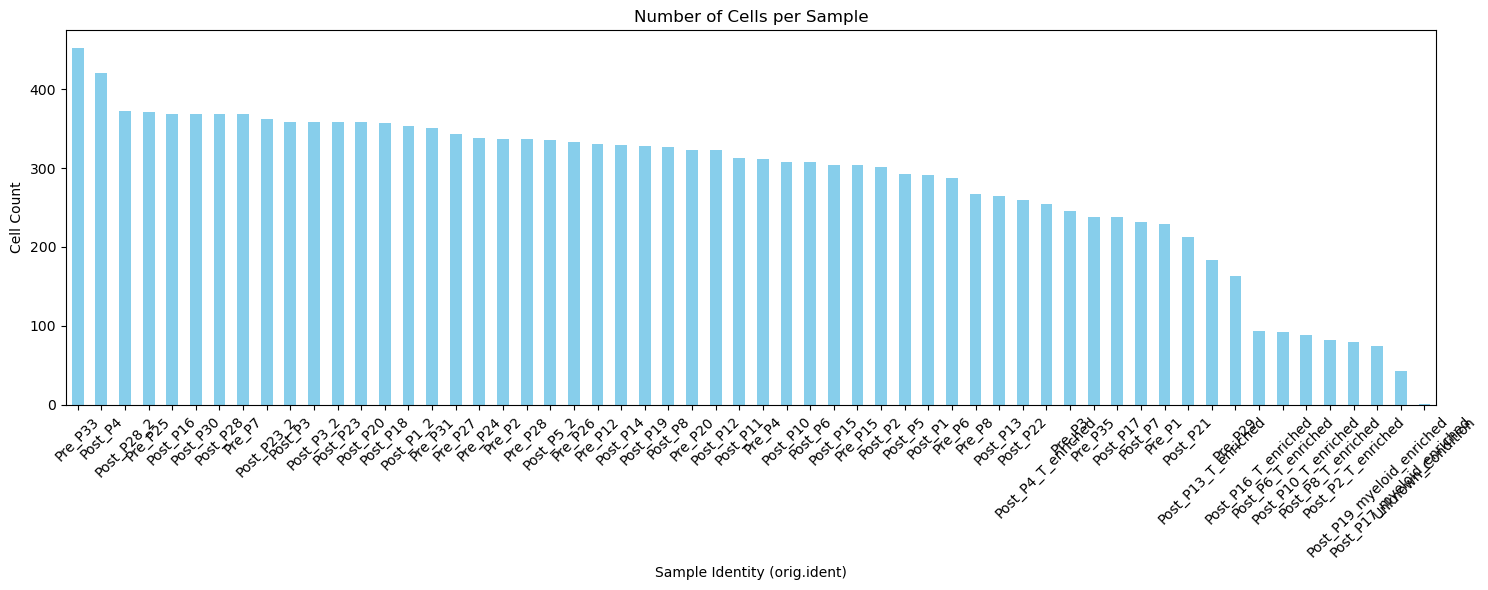

In [4]:
plt.rcParams["figure.figsize"] = (15, 6)
adata.obs['sample_condition'].value_counts().plot(kind='bar', color='skyblue')

plt.title('Number of Cells per Sample')
plt.xlabel('Sample Identity (orig.ident)')
plt.ylabel('Cell Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [52]:
adata.obs.rename(columns={'sample_condition': 'sample'}, inplace=True)
adata.obs

,sample,timepoint,patient_id,Sample name,cell_id,source name,organism,characteristics: patinet ID (Pre=baseline; Post= on treatment),characteristics: response,characteristics: therapy,response
A10_P3_M11,Pre_P1,Pre,P1,Sample 1,A10_P3_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4,1.0
A11_P1_M11,Pre_P1,Pre,P1,Sample 2,A11_P1_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4,1.0
A11_P3_M11,Pre_P1,Pre,P1,Sample 3,A11_P3_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4,1.0
A11_P4_M11,Pre_P1,Pre,P1,Sample 4,A11_P4_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4,1.0
A12_P3_M11,Pre_P1,Pre,P1,Sample 5,A12_P3_M11,Melanoma single cell,Homo sapiens,Pre_P1,Responder,anti-CTLA4,1.0
...,...,...,...,...,...,...,...,...,...,...,...
H6_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6,Sample 16288,H6_P5_M67_L001_T_enriched,Melanoma single cell,Homo sapiens,Post_P6,Non-responder,anti-PD1,0.0
H7_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6,Sample 16289,H7_P5_M67_L001_T_enriched,Melanoma single cell,Homo sapiens,Post_P6,Non-responder,anti-PD1,0.0
H8_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6,Sample 16290,H8_P5_M67_L001_T_enriched,Melanoma single cell,Homo sapiens,Post_P6,Non-responder,anti-PD1,0.0
H9_P5_M67_L001_T_enriched,Post_P6_T_enriched,Post,P6,Sample 16291,H9_P5_M67_L001_T_enriched,Melanoma single cell,Homo sapiens,Post_P6,Non-responder,anti-PD1,0.0


In [53]:
adata.write_h5ad("precise_dataset.h5ad")

In [2]:
adata = sc.read_h5ad("precise_dataset.h5ad")

In [3]:
cells_to_remove = ["Unknown_Cell_0"]

# 2. Create a boolean mask for cells NOT in the removal list
keep_mask = ~adata.obs_names.isin(cells_to_remove)

# 3. Subset the AnnData object (use .copy() to avoid working on a view)
adata_filt = adata[keep_mask, :].copy()

In [4]:
print(adata.obs.shape)
print(adata_filt.obs.shape)


(16292, 11)
(16291, 11)


In [5]:
adata_filt.obs['response'] = adata_filt.obs['response'].astype(int)

In [6]:
sc.pp.log1p(adata_filt)

In [7]:
adata_filt.write_h5ad("precise_dataset.h5ad")

In [2]:
adata_final = sc.read_h5ad("precise_dataset.h5ad")

In [3]:
output_dir = "C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/precise_dataset_result"
precise = Precise(
    adata_final,
    model_name='XGBoostClassifier',
    output_dir=output_dir,
    target_column="response",  # Adjust based on your dataset
    sample_column="sample"
)
prediction_results = precise.cv_prediction()
sample_results, auc, estimators = prediction_results

Starting LOO Prediction with 16291 cells and 55737 features.
Sample column: sample, Target column: response.
Using Leave-One-Out cross-validation with 57 splits.

=== Fold 1 ===
Processed 1 samples
Sample	Label	Score
Post_P1	1.0	0.4021

=== Fold 2 ===
Processed 1 samples
Sample	Label	Score
Post_P1_2	0.0	0.3116

=== Fold 3 ===
Processed 1 samples
Sample	Label	Score
Post_P2	0.0	0.1395

=== Fold 4 ===
Processed 1 samples
Sample	Label	Score
Post_P2_T_enriched	0.0	0.7975

=== Fold 5 ===
Processed 1 samples
Sample	Label	Score
Post_P3	0.0	0.0139

=== Fold 6 ===
Processed 1 samples
Sample	Label	Score
Post_P3_2	0.0	0.0587

=== Fold 7 ===
Processed 1 samples
Sample	Label	Score
Post_P4	1.0	0.4869

=== Fold 8 ===
Processed 1 samples
Sample	Label	Score
Post_P4_T_enriched	1.0	0.3780

=== Fold 9 ===
Processed 1 samples
Sample	Label	Score
Post_P5	0.0	0.6096

=== Fold 10 ===
Processed 1 samples
Sample	Label	Score
Post_P5_2	1.0	0.2173

=== Fold 11 ===
Processed 1 samples
Sample	Label	Score
Post_P6	0.0	0

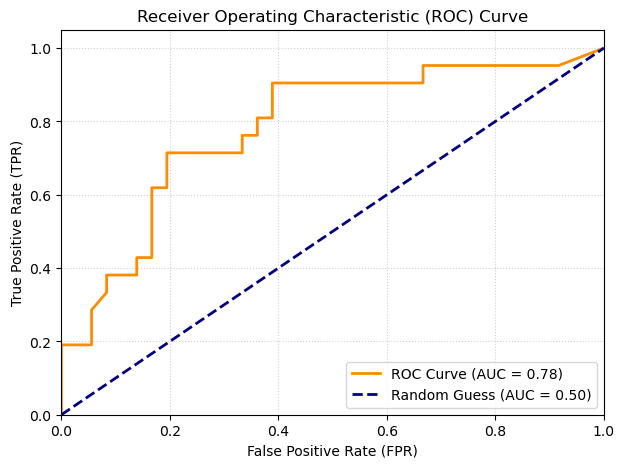

In [11]:
from sklearn.metrics import roc_auc_score, roc_curve
score_df = pd.read_csv("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/precise_dataset_result/loo_results.csv", sep=',')
y_true = score_df['Label']
y_score = score_df['Score']
fpr, tpr, thresholds = roc_curve(y_true, y_score)
auc_score = roc_auc_score(y_true, y_score)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


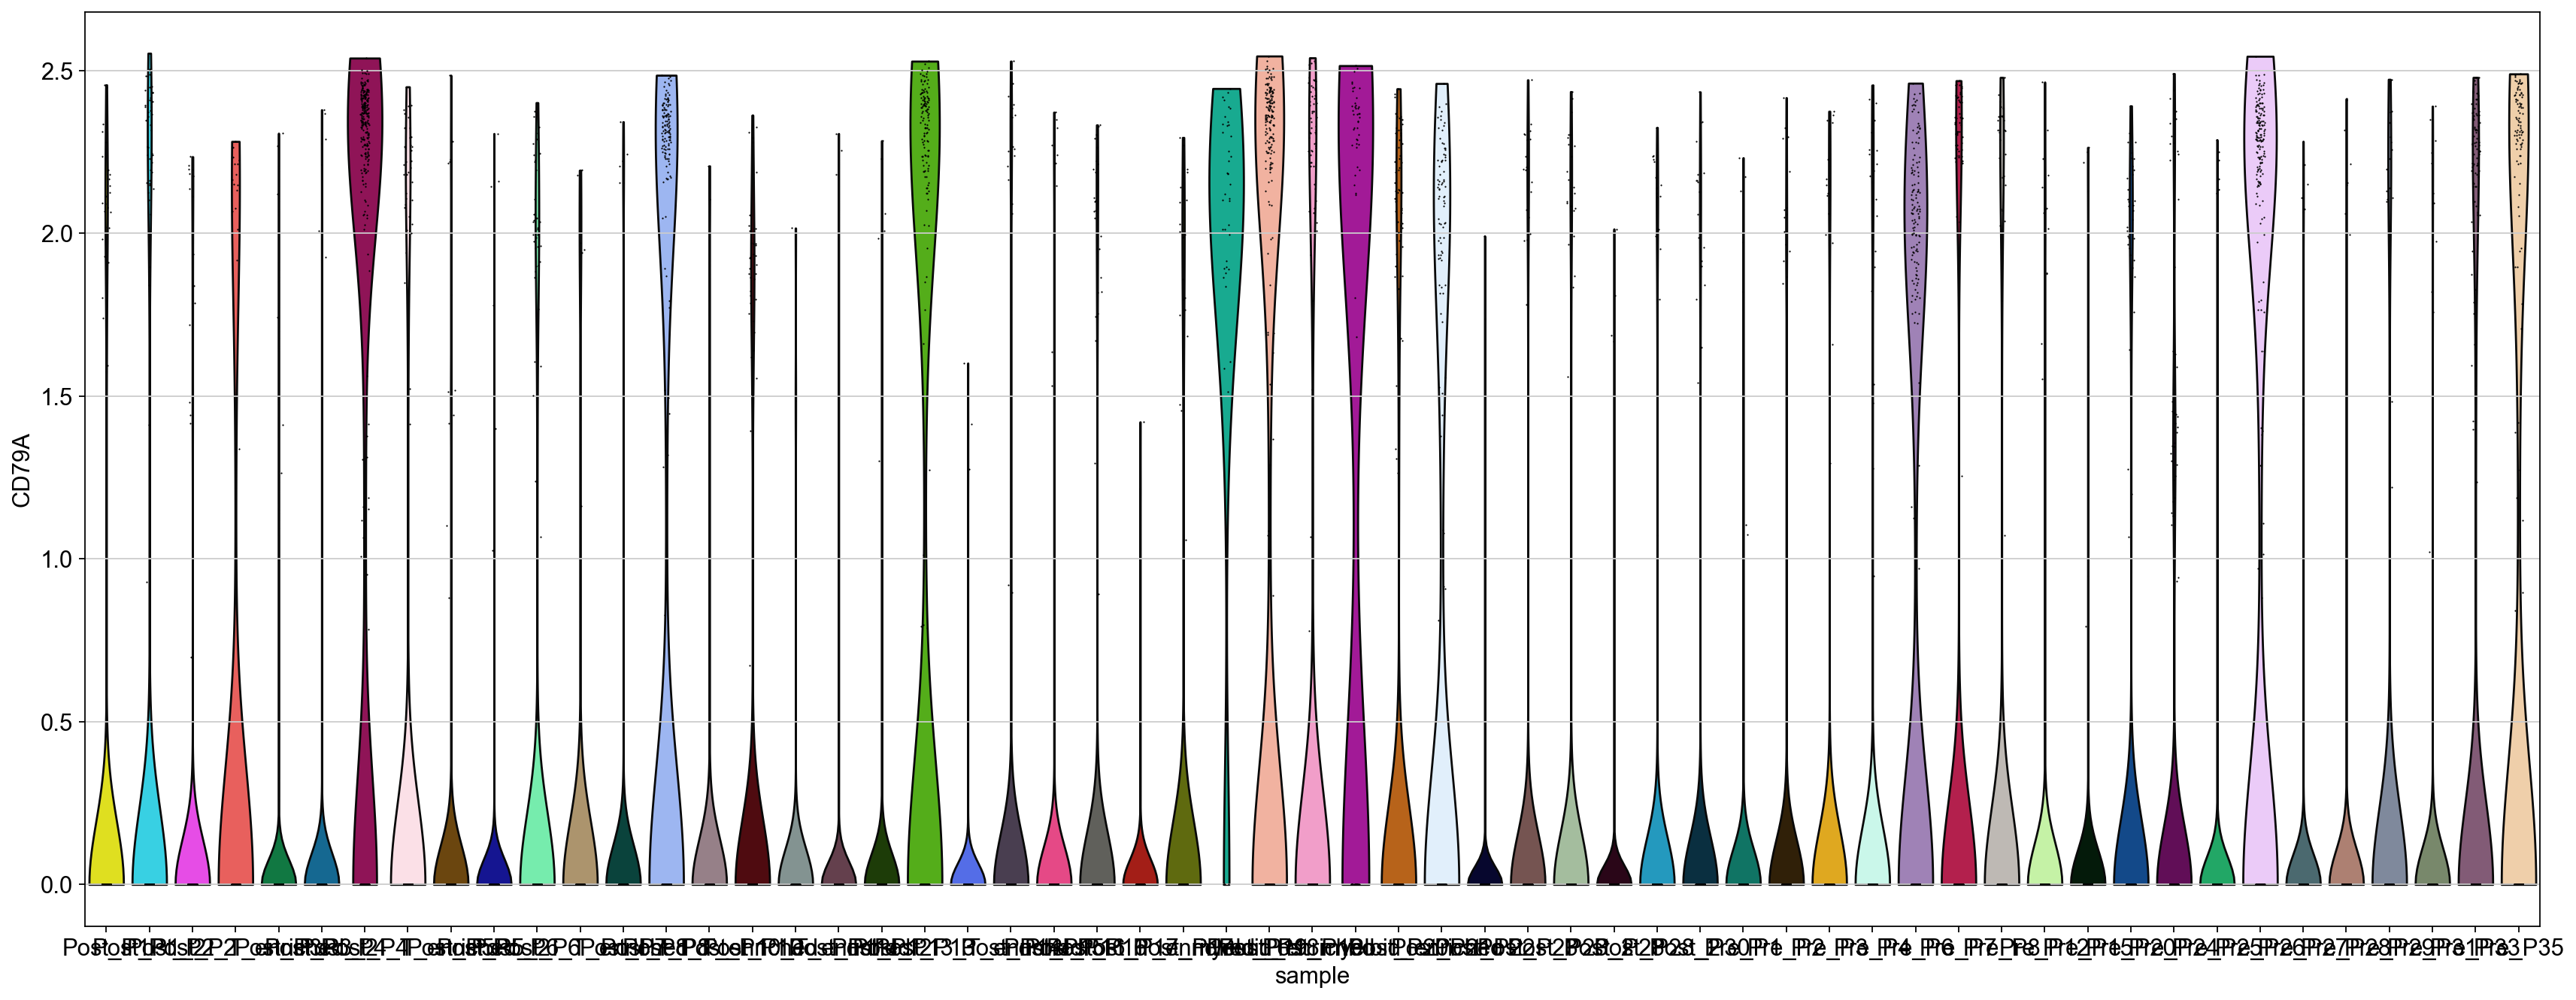

In [14]:
sc.set_figure_params(facecolor='white', figsize=(20, 10))
sc.pl.violin(adata_final, ['CD79A'], groupby="sample")

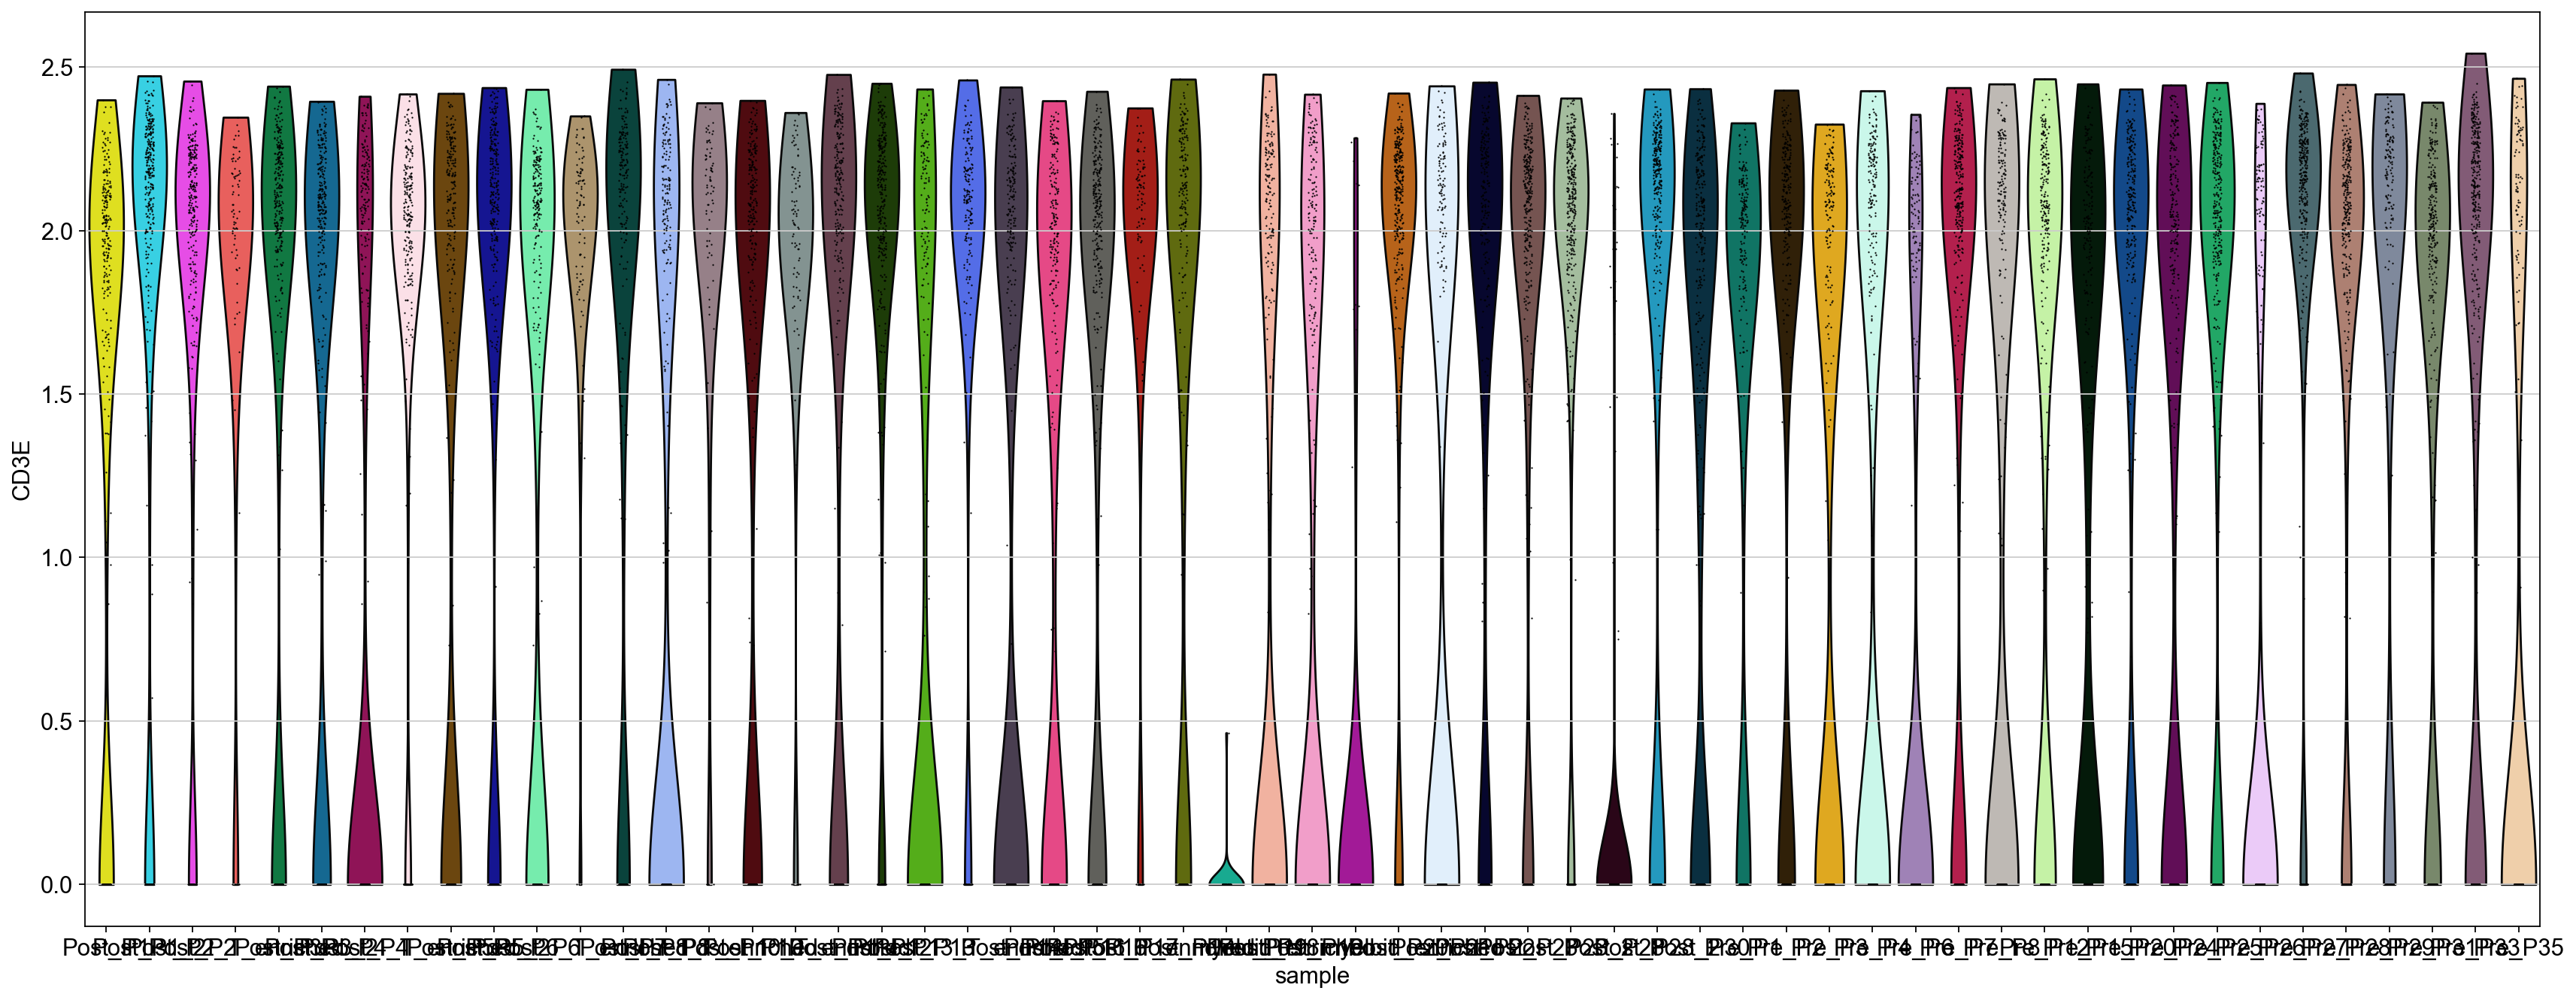

In [15]:
sc.set_figure_params(facecolor='white', figsize=(20, 10))
sc.pl.violin(adata_final, ['CD3E'], groupby="sample")

In [16]:
top_features = precise.choose_top_features(10)
top_features

['HLA-DRB5',
 'EPSTI1',
 'IFI6',
 'HLA-B',
 'GAPDH',
 'LGALS1',
 'RP4-765C7.2',
 'IFI44L',
 'ANXA5',
 'STAT1']

In [2]:
adata_final = sc.read_h5ad("precise_dataset.h5ad")

In [6]:
adata_pre = adata_final[adata_final.obs["timepoint"] == "Pre"].copy()

In [7]:
adata_pre.obs.shape

(5928, 11)

In [8]:
adata_pre.write_h5ad("precise_dataset_pre.h5ad")

In [2]:
adata_pre = sc.read_h5ad("precise_dataset_pre.h5ad")

In [3]:
output_dir = "C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/precise_dataset_result/pre_treatment"
precise = Precise(
    adata_pre,
    model_name='XGBoostClassifier',
    output_dir=output_dir,
    target_column="response",  # Adjust based on your dataset
    sample_column="sample"
)
prediction_results = precise.cv_prediction()
sample_results, auc, estimators = prediction_results

Starting LOO Prediction with 5928 cells and 55737 features.
Sample column: sample, Target column: response.
Using Leave-One-Out cross-validation with 19 splits.

=== Fold 1 ===
Processed 1 samples
Sample	Label	Score
Pre_P1	1.0	0.1135

=== Fold 2 ===
Processed 1 samples
Sample	Label	Score
Pre_P2	0.0	0.4748

=== Fold 3 ===
Processed 1 samples
Sample	Label	Score
Pre_P3	0.0	0.5061

=== Fold 4 ===
Processed 1 samples
Sample	Label	Score
Pre_P4	0.0	0.1350

=== Fold 5 ===
Processed 1 samples
Sample	Label	Score
Pre_P6	0.0	0.3819

=== Fold 6 ===
Processed 1 samples
Sample	Label	Score
Pre_P7	1.0	0.2717

=== Fold 7 ===
Processed 1 samples
Sample	Label	Score
Pre_P8	1.0	0.5318

=== Fold 8 ===
Processed 1 samples
Sample	Label	Score
Pre_P12	0.0	0.5788

=== Fold 9 ===
Processed 1 samples
Sample	Label	Score
Pre_P15	0.0	0.6743

=== Fold 10 ===
Processed 1 samples
Sample	Label	Score
Pre_P20	0.0	0.8328

=== Fold 11 ===
Processed 1 samples
Sample	Label	Score
Pre_P24	1.0	0.7456

=== Fold 12 ===
Processed 1 s

In [4]:
adata_precise = sc.read_h5ad("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/sample_melanoma_adata.h5ad")

In [5]:
adata_precise.shape

(1200, 10082)

In [6]:
output_dir = "C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/precise_dataset_result/h5ad_from_github"
precise = Precise(
    adata_precise,
    model_name='XGBoostClassifier',
    output_dir=output_dir,
    target_column="response",  # Adjust based on your dataset
    sample_column="sample"
)
prediction_results = precise.cv_prediction()
sample_results, auc, estimators = prediction_results

Starting LOO Prediction with 1200 cells and 10082 features.
Sample column: sample, Target column: response.
Using Leave-One-Out cross-validation with 48 splits.

=== Fold 1 ===
Processed 1 samples
Sample	Label	Score
Post_P1	1.0	0.0800

=== Fold 2 ===
Processed 1 samples
Sample	Label	Score
Post_P1_2	0.0	0.1200

=== Fold 3 ===
Processed 1 samples
Sample	Label	Score
Post_P2	0.0	0.2000

=== Fold 4 ===
Processed 1 samples
Sample	Label	Score
Post_P3	0.0	0.1600

=== Fold 5 ===
Processed 1 samples
Sample	Label	Score
Post_P3_2	0.0	0.3600

=== Fold 6 ===
Processed 1 samples
Sample	Label	Score
Post_P4	1.0	0.5600

=== Fold 7 ===
Processed 1 samples
Sample	Label	Score
Post_P5	0.0	0.2800

=== Fold 8 ===
Processed 1 samples
Sample	Label	Score
Post_P5_2	1.0	0.0400

=== Fold 9 ===
Processed 1 samples
Sample	Label	Score
Post_P6	0.0	0.0000

=== Fold 10 ===
Processed 1 samples
Sample	Label	Score
Post_P7	1.0	0.1200

=== Fold 11 ===
Processed 1 samples
Sample	Label	Score
Post_P8	1.0	0.4000

=== Fold 12 ===
